# SmartSupply AI — Analyse exploratoire du dataset ML (phase 5)

**Objectif :** comprendre le dataset *avant* d'entraîner un modèle.

- Une ligne = **un produit observé à la fin du jour `as_of_date`**.
- Cible : **`target_demand_next_7d`** = unités **demandées** pendant les 7 jours suivants.
- Toutes les variables n'utilisent que des informations connues à `as_of_date` (testé dans `tests/unit/test_features.py`).

Questions auxquelles ce notebook répond :
1. Le dataset est-il propre (doublons, valeurs manquantes, types) ?
2. À quoi ressemble la cible ? Y a-t-il des produits très différents ?
3. Quels effets sont visibles : tendance, saisonnalité, jour de la semaine, promotions, ruptures ?
4. Quelles variables sont liées à la cible ?
5. Quel niveau d'erreur atteint une méthode naïve ? (c'est le score à battre en phase 6)
6. Le découpage train / validation / test est-il cohérent ?

> ⚠️ Données **100 % synthétiques** : les conclusions décrivent le monde simulé, pas une vraie entreprise.

## 0. Préparation et chargement

La première cellule vérifie que les bibliothèques nécessaires sont présentes **dans le noyau utilisé**
et les installe si besoin. Le notebook ne dépend pas du paquet `smartsupply` : il lit directement
le fichier Parquet exporté par `python -m smartsupply.features.build --export`.

In [1]:
import importlib.util
import subprocess
import sys

print("Python utilisé :", sys.executable)
requis = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "pyarrow": "pyarrow"}
manquants = [pip for module, pip in requis.items() if importlib.util.find_spec(module) is None]
if manquants:
    print("Installation de :", ", ".join(manquants))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *manquants])
    print("Installé. Si une erreur d'import suit, redémarre le noyau (Restart) puis relance tout.")
else:
    print("Toutes les bibliothèques sont présentes.")

Python utilisé : c:\Users\KOURO\anaconda3\envs\smartsupply\python.exe
Toutes les bibliothèques sont présentes.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

# Mêmes définitions que src/smartsupply/features/build.py et split.py
TARGET = "target_demand_next_7d"
FEATURES = [
    "demand_lag_1", "demand_lag_7", "demand_lag_14", "demand_lag_28",
    "demand_rolling_mean_7", "demand_rolling_mean_28", "demand_rolling_std_28",
    "lost_sales_rolling_7",
    "price_as_of", "promotion_active", "discount_pct",
    "promo_days_next_7", "promo_max_discount_next_7",
    "weekday", "month", "day_of_year", "is_weekend",
    "stock_as_of", "incoming_qty_known_as_of", "supplier_lead_time_known_as_of",
]
PLAN = {   # découpage chronologique (README 7.4), avec un mois de séparation
    "train": ("2024-01-01", "2025-04-30"),
    "validation": ("2025-06-01", "2025-08-31"),
    "test": ("2025-10-01", "2025-12-31"),
}

def chronological_split(df):
    labeled = df[df[TARGET].notna()]
    return {name: labeled[labeled["as_of_date"].between(pd.Timestamp(a), pd.Timestamp(b))].reset_index(drop=True)
            for name, (a, b) in PLAN.items()}

# Dossier du projet : on remonte depuis le dossier courant jusqu'à trouver data/datasets
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "datasets").exists()), None)
assert ROOT, "Dossier data/datasets introuvable : lance d'abord `python -m smartsupply.features.build --export`"
files = sorted((ROOT / "data" / "datasets").glob("features_*.parquet"), key=lambda p: p.stat().st_mtime)
assert files, "Aucun dataset : lance d'abord `python -m smartsupply.features.build --export`"
path = files[-1]

df = pd.read_parquet(path)
df["as_of_date"] = pd.to_datetime(df["as_of_date"])
print(f"Fichier : {path.name}")
print(f"{len(df):,} lignes x {df.shape[1]} colonnes | {df['product_id'].nunique()} produits | "
      f"{df['as_of_date'].min():%Y-%m-%d} -> {df['as_of_date'].max():%Y-%m-%d}")
df.head()

Fichier : features_20260102_27ca0cb3.parquet
35,300 lignes x 25 colonnes | 50 produits | 2024-01-28 -> 2026-01-02


,as_of_date,product_id,category,supplier_id,demand_lag_1,demand_lag_7,demand_lag_14,demand_lag_28,demand_rolling_mean_7,demand_rolling_mean_28,demand_rolling_std_28,lost_sales_rolling_7,price_as_of,promotion_active,discount_pct,promo_days_next_7,promo_max_discount_next_7,weekday,month,day_of_year,is_weekend,stock_as_of,incoming_qty_known_as_of,supplier_lead_time_known_as_of,target_demand_next_7d
0,2024-01-28,1,Électroménager,8,3,3,4,9,5.571429,4.321429,2.667411,0,29.16,False,0.00,0,0.00,6,1,28,True,36,27,8,26
1,2024-01-28,2,Électroménager,1,9,16,16,15,18.571429,15.178571,5.121151,10,11.33,True,0.15,0,0.00,6,1,28,True,44,88,24,74
2,2024-01-28,3,Boissons,2,19,38,46,42,30.714286,30.500000,12.164003,0,7.87,True,0.15,7,0.15,6,1,28,True,1224,0,30,302
3,2024-01-28,4,Papeterie,6,1,3,2,2,2.571429,2.642857,1.830084,0,13.03,False,0.00,0,0.00,6,1,28,True,28,27,8,13
4,2024-01-28,5,Épicerie,6,3,6,5,3,11.142857,6.107143,4.366024,23,23.04,True,0.30,4,0.30,6,1,28,True,52,32,8,45


## 1. Qualité du dataset

In [3]:
quality = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs manquantes": df.isna().sum(),
    "nb valeurs distinctes": df.nunique(),
})
print("Doublons (as_of_date, product_id) :", df.duplicated(["as_of_date", "product_id"]).sum())
lignes_par_jour = df.groupby("as_of_date")["product_id"].count()
print("Produits par jour : min", lignes_par_jour.min(), "/ max", lignes_par_jour.max())
quality

Doublons (as_of_date, product_id) : 0
Produits par jour : min 50 / max 50


,type,valeurs manquantes,nb valeurs distinctes
as_of_date,datetime64[s],0,706
product_id,int64,0,50
category,str,0,8
supplier_id,int64,0,10
demand_lag_1,int64,0,139
demand_lag_7,int64,0,139
demand_lag_14,int64,0,139
demand_lag_28,int64,0,139
demand_rolling_mean_7,float64,0,615
demand_rolling_mean_28,float64,0,1862


**À retenir :** aucun doublon, aucune valeur manquante (l'export ne contient que les lignes dont la cible est connue), et chaque jour contient tous les produits.

## 2. La cible : demande des 7 prochains jours

count    35300.0
mean        84.3
std         87.5
min          0.0
25%         32.0
50%         56.0
75%        105.0
max        834.0
Name: target_demand_next_7d, dtype: float64


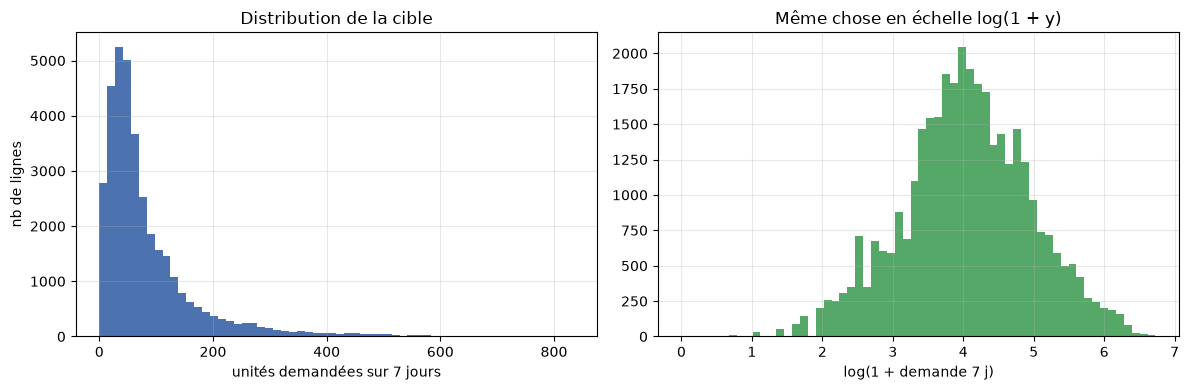

In [4]:
y = df[TARGET].astype(float)
print(y.describe().round(1))

fig, axes = plt.subplots(1, 2)
axes[0].hist(y, bins=60, color="#4C72B0")
axes[0].set(title="Distribution de la cible", xlabel="unités demandées sur 7 jours", ylabel="nb de lignes")
axes[1].hist(np.log1p(y), bins=60, color="#55A868")
axes[1].set(title="Même chose en échelle log(1 + y)", xlabel="log(1 + demande 7 j)")
plt.tight_layout(); plt.show()

**Lecture :** la distribution est **asymétrique** : beaucoup de produits vendent peu, quelques-uns vendent beaucoup.
En échelle log elle devient plus symétrique. Conséquence pour la phase 6 :
- une erreur moyenne (MAE) globale sera dominée par les gros produits ;
- il faudra aussi regarder le **WAPE** et les erreurs **par segment** (produits lents vs rapides).

Top 5 produits :


,product_id,category,demande_moy_7j
0,37,Boissons,390.298867
1,3,Boissons,364.090652
2,11,Bricolage,252.985836
3,18,Boissons,221.174221
4,22,Entretien,190.596317


5 produits les plus lents :


,product_id,category,demande_moy_7j
45,33,Boissons,17.790368
46,35,Papeterie,17.172805
47,14,Épicerie,11.842776
48,9,Textile,10.426346
49,10,Boissons,7.321530


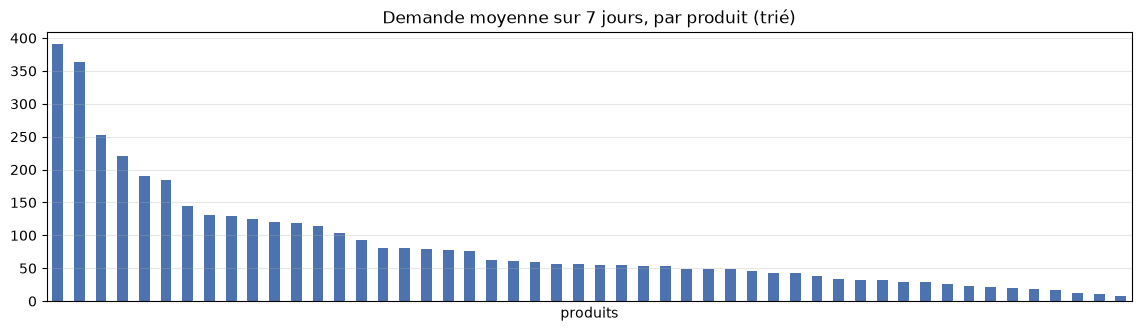

In [5]:
par_produit = (df.groupby(["product_id", "category"])[TARGET].mean().astype(float)
                 .sort_values(ascending=False).reset_index(name="demande_moy_7j"))
print("Top 5 produits :"); display(par_produit.head())
print("5 produits les plus lents :"); display(par_produit.tail())

par_produit["demande_moy_7j"].plot(kind="bar", color="#4C72B0", figsize=(14, 3.5),
                                    title="Demande moyenne sur 7 jours, par produit (trié)")
plt.xticks([]); plt.xlabel("produits"); plt.show()

**Lecture :** l'écart entre produits rapides et lents est grand (un facteur 10 ou plus).
C'est exactement ce que le simulateur a voulu reproduire (loi log-normale de la demande de base).

## 3. Évolution dans le temps : tendance et saisonnalité

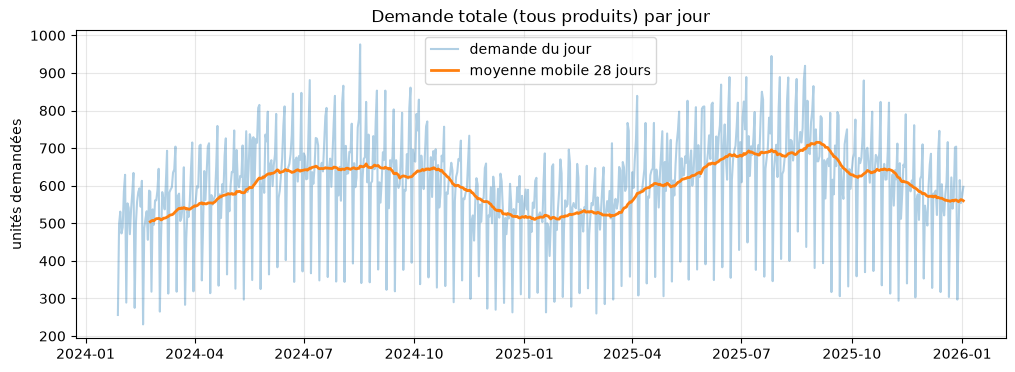

In [6]:
total = df.groupby("as_of_date")["demand_lag_1"].sum()   # demande totale du jour D
fig, ax = plt.subplots()
ax.plot(total.index, total, alpha=0.35, label="demande du jour")
ax.plot(total.index, total.rolling(28).mean(), lw=2, label="moyenne mobile 28 jours")
ax.set(title="Demande totale (tous produits) par jour", ylabel="unités demandées")
ax.legend(); plt.show()

**Lecture :** on voit (1) une forte variation **d'un jour à l'autre** (jour de la semaine + hasard),
(2) des **vagues saisonnières** et (3) une légère **tendance** d'une année à l'autre.

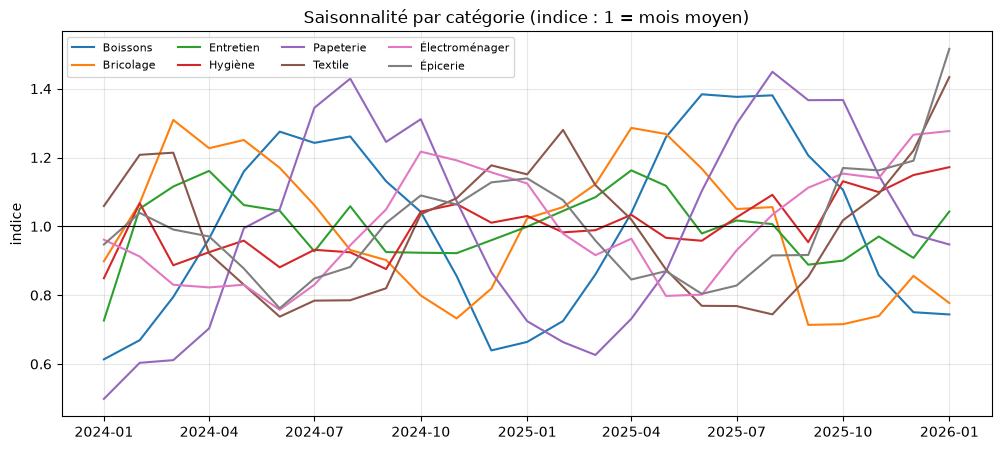

In [7]:
mensuel = (df.assign(mois=df["as_of_date"].dt.to_period("M"))
             .groupby(["mois", "category"])["demand_lag_1"].mean().unstack())
# moyenne par produit et par jour : les mois incomplets (début / fin) ne faussent pas l'indice
indice = mensuel / mensuel.mean()          # 1.0 = mois moyen de la catégorie
fig, ax = plt.subplots(figsize=(12, 5))
for cat in indice.columns:
    ax.plot(indice.index.to_timestamp(), indice[cat], label=cat)
ax.axhline(1, color="black", lw=0.8)
ax.set(title="Saisonnalité par catégorie (indice : 1 = mois moyen)", ylabel="indice")
ax.legend(ncol=4, fontsize=8); plt.show()

**Lecture :** chaque catégorie a **son propre pic** : Boissons l'été, Papeterie à la rentrée,
Électroménager en fin d'année, Textile en janvier… Hygiène est presque plate.
➡️ Le modèle doit savoir **quelle catégorie** et **quelle période de l'année** : d'où `category`, `month`, `day_of_year`.

## 4. Effet du jour de la semaine

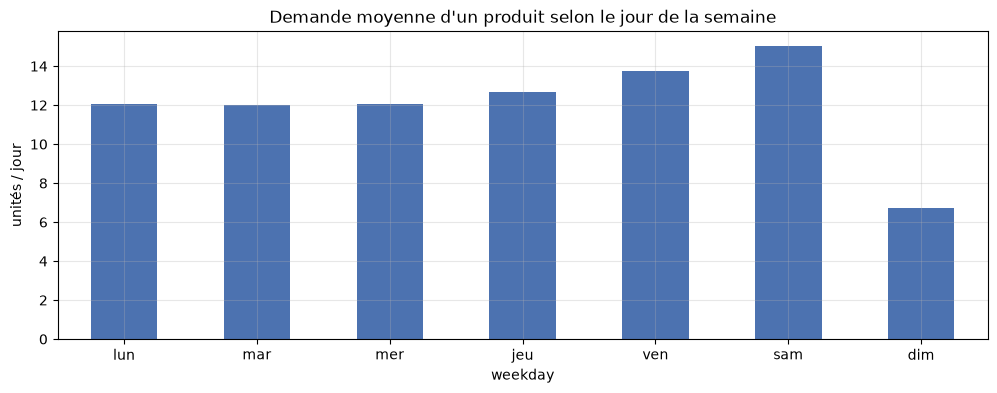

In [8]:
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
par_jour = df.groupby("weekday")["demand_lag_1"].mean()
ax = par_jour.plot(kind="bar", color="#4C72B0", title="Demande moyenne d'un produit selon le jour de la semaine")
ax.set_xticklabels(jours, rotation=0); ax.set_ylabel("unités / jour"); plt.show()

**Lecture :** pic le **samedi**, creux net le **dimanche**.
Pour une cible sur 7 jours, cet effet s'annule en grande partie (une semaine contient toujours un samedi et un dimanche),
mais il rend les **lags d'un seul jour** très bruités : `demand_lag_1` d'un dimanche sous-estime la demande normale.
C'est pour cela que `demand_lag_7` (même jour de la semaine) et les **moyennes mobiles** sont plus fiables.

## 5. Effet des promotions (connues à l'avance)

                      count  mean   50%
promo_a_venir                          
pas de promo        30095.0  0.97  0.96
promo dans les 7 j   5205.0  1.29  1.24


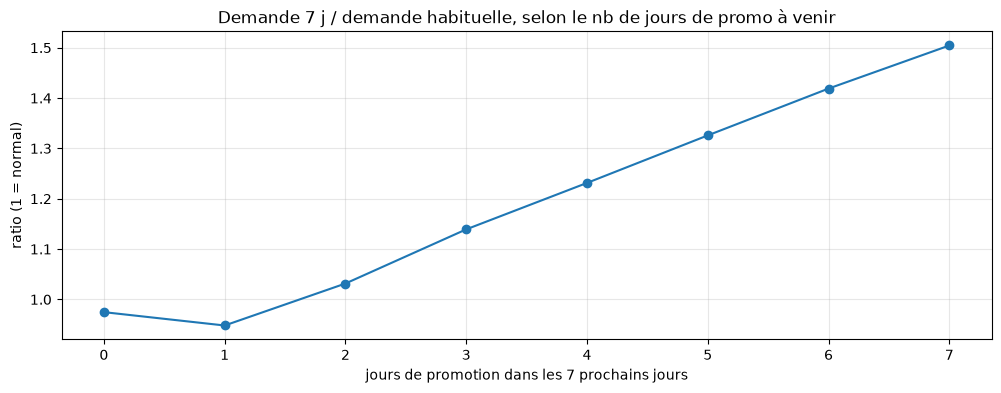

In [9]:
promo = df.assign(promo_a_venir=np.where(df["promo_days_next_7"] > 0, "promo dans les 7 j", "pas de promo"))
# On compare à la demande "habituelle" du produit pour neutraliser l'effet gros/petit produit.
promo["ratio"] = promo[TARGET].astype(float) / (7 * promo["demand_rolling_mean_28"]).replace(0, np.nan)
print(promo.groupby("promo_a_venir")["ratio"].describe()[["count", "mean", "50%"]].round(2))

par_jours = promo.groupby("promo_days_next_7")["ratio"].mean()
ax = par_jours.plot(marker="o", title="Demande 7 j / demande habituelle, selon le nb de jours de promo à venir")
ax.set(xlabel="jours de promotion dans les 7 prochains jours", ylabel="ratio (1 = normal)"); plt.show()

**Lecture :** quand une promotion est **annoncée** pour la semaine suivante, la demande grimpe nettement,
et d'autant plus que la promo couvre de jours.
➡️ `promo_days_next_7` et `promo_max_discount_next_7` sont des variables **légitimes** (connues à D) et très utiles.

## 6. Ruptures : demande ≠ ventes

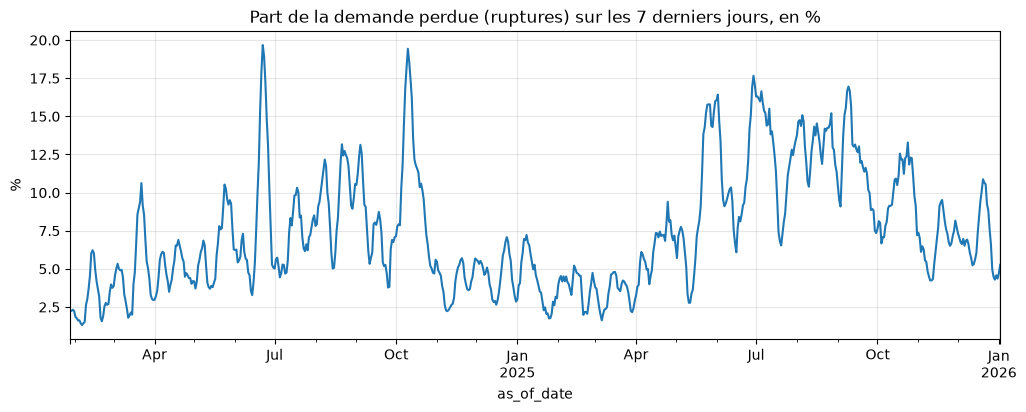

Lignes avec rupture récente : 33.1 %
Lignes avec stock nul à D : 0.3 %


In [10]:
taux = (df.groupby("as_of_date")["lost_sales_rolling_7"].sum()
        / (7 * df.groupby("as_of_date")["demand_rolling_mean_7"].sum())).rename("part perdue")
ax = (100 * taux).plot(title="Part de la demande perdue (ruptures) sur les 7 derniers jours, en %")
ax.set_ylabel("%"); plt.show()

print("Lignes avec rupture récente :", f"{100 * (df['lost_sales_rolling_7'] > 0).mean():.1f} %")
print("Lignes avec stock nul à D :", f"{100 * (df['stock_as_of'] == 0).mean():.1f} %")

**Lecture :** une partie de la demande n'est pas servie, surtout aux pics saisonniers (la règle de réapprovisionnement
ne connaît pas la saison). C'est pour cela que la cible est la **demande** (`requested_qty`) et non les ventes :
un produit en rupture a des ventes nulles mais une demande bien réelle.

## 7. Relations entre variables et cible

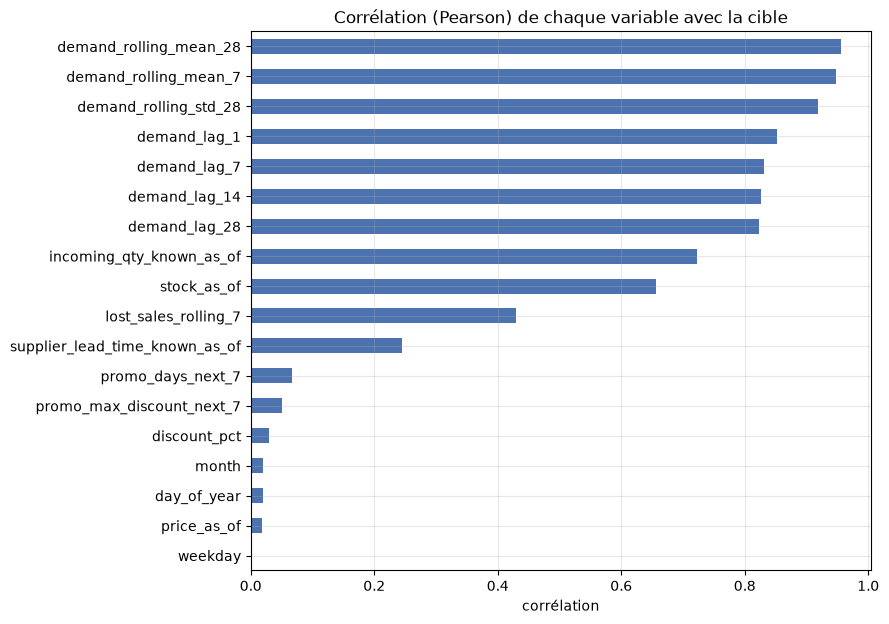

In [11]:
num = [c for c in FEATURES if df[c].dtype != bool] + [TARGET]
corr = df[num].astype(float).corr()[TARGET].drop(TARGET).sort_values()
ax = corr.plot(kind="barh", figsize=(8, 7), color=np.where(corr > 0, "#4C72B0", "#C44E52"),
               title="Corrélation (Pearson) de chaque variable avec la cible")
ax.set_xlabel("corrélation"); plt.show()

**Lecture :**
- Les **moyennes mobiles** (`demand_rolling_mean_28`, `_7`) sont de loin les plus liées à la cible : la demande passée prédit la demande future.
- `stock_as_of` et `incoming_qty_known_as_of` sont aussi corrélés… mais surtout parce que les **gros produits ont de gros stocks**.
  Corrélation ≠ causalité : on vérifiera leur vrai apport avec le modèle.
- Les variables calendaires et promotionnelles ont une corrélation **linéaire** quasi nulle, alors que la saisonnalité
  (section 3) et l'effet promo (section 5, +30 % environ) existent bien : leur effet est **relatif** à chaque produit
  et non linéaire. Un modèle d'arbres (LightGBM) saura l'exploiter, une régression linéaire beaucoup moins.
  ➡️ Une corrélation faible ne veut pas dire « variable inutile ».

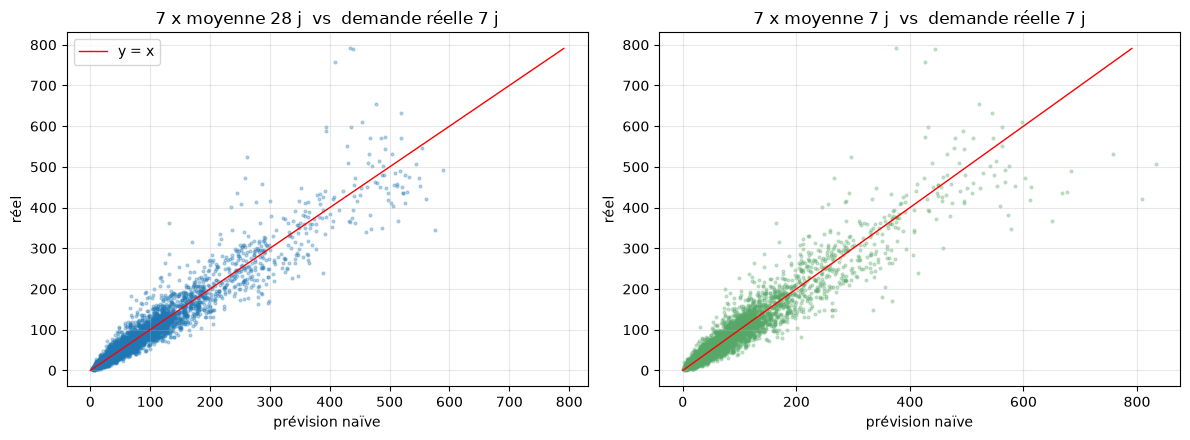

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sample = df.sample(min(5000, len(df)), random_state=42)
axes[0].scatter(7 * sample["demand_rolling_mean_28"], sample[TARGET], s=4, alpha=0.3)
lim = float(sample[TARGET].max())
axes[0].plot([0, lim], [0, lim], color="red", lw=1, label="y = x")
axes[0].set(title="7 x moyenne 28 j  vs  demande réelle 7 j", xlabel="prévision naïve", ylabel="réel"); axes[0].legend()
axes[1].scatter(7 * sample["demand_rolling_mean_7"], sample[TARGET], s=4, alpha=0.3, color="#55A868")
axes[1].plot([0, lim], [0, lim], color="red", lw=1)
axes[1].set(title="7 x moyenne 7 j  vs  demande réelle 7 j", xlabel="prévision naïve", ylabel="réel")
plt.tight_layout(); plt.show()

## 8. Le score à battre : méthodes naïves

Avant tout modèle, on mesure l'erreur de prévisions **sans apprentissage**, sur la période de **validation** :
- **naïve 7 j** : `7 × moyenne des 7 derniers jours`
- **naïve 28 j** : `7 × moyenne des 28 derniers jours`

Métriques :
- **MAE** : erreur moyenne en unités ;
- **WAPE** = Σ|erreur| / Σ réel : erreur relative globale (moins piégée par les petits volumes qu'une moyenne de pourcentages) ;
- **Biais** = Σ(prévu − réel) / Σ réel : négatif = on sous-estime (dangereux : ruptures).

In [13]:
def scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {"MAE": np.mean(np.abs(y_pred - y_true)),
            "WAPE %": 100 * np.abs(y_pred - y_true).sum() / y_true.sum(),
            "Biais %": 100 * (y_pred - y_true).sum() / y_true.sum()}

parts = chronological_split(df)
val = parts["validation"]
baselines = pd.DataFrame({
    "naïve 7 j": scores(val[TARGET], 7 * val["demand_rolling_mean_7"]),
    "naïve 28 j": scores(val[TARGET], 7 * val["demand_rolling_mean_28"]),
}).T.round(2)
baselines

,MAE,WAPE %,Biais %
naïve 7 j,18.55,19.12,-0.06
naïve 28 j,15.93,16.42,-1.36


**Lecture :** c'est la **barre à franchir** en phase 6. Un modèle qui ne fait pas mieux que ces règles simples
sur la validation n'a aucun intérêt (critère de validation du README, section 8).
Note : sur l'ensemble de la validation, le biais des méthodes naïves est proche de 0, mais il cache des erreurs
**dans les deux sens** : elles sous-estiment pendant les montées (saison, promotions annoncées) et surestiment
pendant les baisses, car elles ne regardent que le passé. Le modèle devra corriger ces deux cas.

## 9. Découpage chronologique train / validation / test

train        22950 lignes  2024-01-28 -> 2025-04-30
validation    4600 lignes  2025-06-01 -> 2025-08-31
test          4600 lignes  2025-10-01 -> 2025-12-31


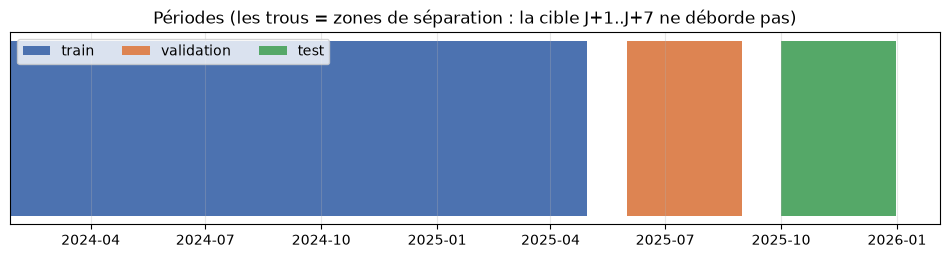

In [14]:
for name, part in parts.items():
    print(f"{name:<11} {len(part):>6} lignes  {part['as_of_date'].min():%Y-%m-%d} -> {part['as_of_date'].max():%Y-%m-%d}")

fig, ax = plt.subplots(figsize=(12, 2.5))
couleurs = {"train": "#4C72B0", "validation": "#DD8452", "test": "#55A868"}
for i, (name, part) in enumerate(parts.items()):
    d = pd.to_datetime(part["as_of_date"])
    ax.barh(0, (d.max() - d.min()).days, left=d.min(), color=couleurs[name], label=name)
ax.set_yticks([]); ax.legend(loc="upper left", ncol=3)
ax.set_title("Périodes (les trous = zones de séparation : la cible J+1..J+7 ne déborde pas)")
plt.show()

**Lecture :** train (fév. 2024 → avril 2025), validation (été 2025), test (fin 2025), avec un mois vide entre chaque.
Le **test n'est utilisé qu'une seule fois**, à la toute fin, pour une évaluation honnête.

## 10. Conclusions pour la phase 6

| Constat | Décision pour le modèle |
|---|---|
| Cible asymétrique, produits très différents | Suivre WAPE + MAE par segment ; essayer une cible en log |
| Saisonnalité propre à chaque catégorie, non linéaire | Garder `category`, `month`, `day_of_year` ; préférer LightGBM |
| Fort effet du jour de la semaine sur les lags d'1 jour | S'appuyer sur moyennes mobiles et `demand_lag_7` |
| Promotions annoncées → forte hausse | `promo_days_next_7`, `promo_max_discount_next_7` sont clés |
| Ruptures pendant les pics | Cible = demande, pas ventes (déjà le cas) |
| Méthodes naïves = score de référence | Le modèle doit battre la meilleure des deux sur la validation |